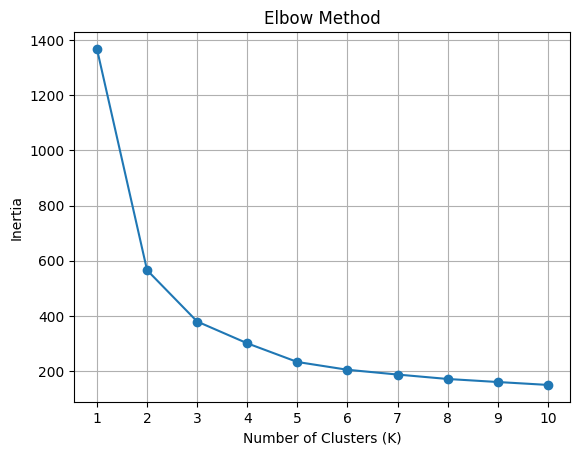

Optimal K = 3
Cluster Centroids:
 [[ 0.66097295  0.8169259  -0.28620559 -0.37431308]
 [ 0.65722922 -1.09998045  1.15886506  1.0917612 ]
 [-1.04805941  0.48655336 -0.89121603 -0.77061658]]


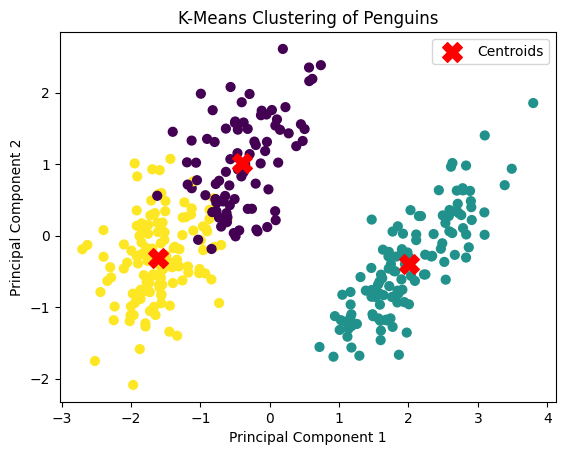

In [2]:

# K-Means Clustering using Penguins Dataset

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Load Dataset
df = pd.read_csv("penguins.csv")

# 2. Data Preprocessing
features = ['bill_length_mm', 'bill_depth_mm',
            'flipper_length_mm', 'body_mass_g']

data = df[features].dropna()

scaler = StandardScaler()
X = scaler.fit_transform(data)

# 3. Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

# 4. Perform K-Means Clustering
# Choose K by observing the elbow plot
optimal_k = 3

kmeans = KMeans(n_clusters=optimal_k,
                random_state=42, n_init=10)

labels = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

print("Optimal K =", optimal_k)
print("Cluster Centroids:\n", centroids)

# 5. Visualize Clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

centroids_pca = pca.transform(centroids)

plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=labels, cmap='viridis', s=40)

plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            color='red', marker='X', s=200,
            label='Centroids')

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Penguins")
plt.legend()
plt.show()
